In [1]:
import pandas as pd
import numpy as np
import itertools
from collections import Counter

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
file_path = "online_retail_II.xlsx"

excel_file = pd.ExcelFile(file_path)

print(excel_file.sheet_names)

['Year 2009-2010', 'Year 2010-2011']


In [4]:
df1 = pd.read_excel(file_path, sheet_name="Year 2009-2010")

df2 = pd.read_excel(file_path, sheet_name="Year 2010-2011")

print("First sheet shape:", df1.shape)
print("Second sheet shape:", df2.shape)

First sheet shape: (525461, 8)
Second sheet shape: (541910, 8)


In [5]:
df = pd.concat([df1, df2], ignore_index=True)

print("Combined Dataset Shape:", df.shape)

Combined Dataset Shape: (1067371, 8)


In [6]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [7]:
df.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [9]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [10]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 34335


In [11]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394028544,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


In [12]:
df_clean = df.copy()

print("Original Dataset:", df_clean.shape)

Original Dataset: (1067371, 8)


In [13]:
df_clean = df_clean.dropna(
    subset=["Invoice", "StockCode", "Description"]
)

print("After removing missing values:", df_clean.shape)

After removing missing values: (1062989, 8)


In [14]:
df_clean["Invoice"] = df_clean["Invoice"].astype(str)

df_clean = df_clean[
    ~df_clean["Invoice"].str.startswith("C")
]

print("After removing cancelled invoices:", df_clean.shape)

After removing cancelled invoices: (1043495, 8)


In [15]:
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["Price"] > 0)
]

print("After removing invalid transactions:", df_clean.shape)

After removing invalid transactions: (1041670, 8)


In [16]:
print("Final Dataset Shape:", df_clean.shape)

print("Missing Values:")
print(df_clean.isnull().sum())

df_clean.head()

Final Dataset Shape: (1041670, 8)
Missing Values:
Invoice             0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
Price               0
Customer ID    236121
Country             0
dtype: int64


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [17]:
total_orders = df_clean["Invoice"].nunique()

print("Total Unique Orders:", total_orders)

Total Unique Orders: 40077


In [18]:
total_products = df_clean["Description"].nunique()

print("Total Unique Products:", total_products)

Total Unique Products: 5399


In [19]:
total_transactions = len(df_clean)

print("Total Transactions:", total_transactions)

Total Transactions: 1041670


In [20]:
basket_size = df_clean.groupby("Invoice")["Description"].nunique()

print(basket_size.head(10))

Invoice
489434     8
489435     4
489436    19
489437    23
489438    17
489439    19
489440     2
489441     4
489442    23
489443     7
Name: Description, dtype: int64


In [21]:
average_basket_size = basket_size.mean()

print("Average Products Per Order:", round(average_basket_size, 2))

Average Products Per Order: 24.85


In [22]:
basket = (
    df_clean.groupby("Invoice")["Description"]
    .apply(lambda x: list(set(x)))
    .to_dict()
)

print("Total Baskets:", len(basket))

Total Baskets: 40077


In [23]:
for invoice, products in list(basket.items())[:5]:
    print("Invoice:", invoice)
    print("Products:", products)
    print("-" * 50)

Invoice: 489434
Products: ['RECORD FRAME 7" SINGLE SIZE ', 'STRAWBERRY CERAMIC TRINKET BOX', 'SAVE THE PLANET MUG', 'PINK DOUGHNUT TRINKET POT ', ' WHITE CHERRY LIGHTS', 'FANCY FONT HOME SWEET HOME DOORMAT', '15CM CHRISTMAS GLASS BALL 20 LIGHTS', 'PINK CHERRY LIGHTS']
--------------------------------------------------
Invoice: 489435
Products: ['HEART MEASURING SPOONS LARGE', 'LUNCHBOX WITH CUTLERY FAIRY CAKES ', 'CAT BOWL ', 'DOG BOWL , CHASING BALL DESIGN']
--------------------------------------------------
Invoice: 489436
Products: ['PIZZA PLATE IN BOX', 'ASSORTED COLOUR BIRD ORNAMENT', 'AREA PATROLLED METAL SIGN', 'BISCUITS SMALL BOWL LIGHT BLUE', 'FULL ENGLISH BREAKFAST PLATE', 'LOVE BUILDING BLOCK WORD', 'SET OF 3 BLACK FLYING DUCKS', ' PEACE WOODEN BLOCK LETTERS', 'BATH BUILDING BLOCK WORD', 'DOOR MAT BLACK FLOCK ', 'SCOTTIE DOG HOT WATER BOTTLE', 'HOME BUILDING BLOCK WORD', 'CHRISTMAS CRAFT WHITE FAIRY ', 'BLACK DINER WALL CLOCK', 'HEART FILIGREE DOVE LARGE', 'CLASSIC WHITE FRA

In [24]:
basket_sizes = [len(products) for products in basket.values()]

print("Minimum Products:", min(basket_sizes))
print("Maximum Products:", max(basket_sizes))
print("Average Products:", round(np.mean(basket_sizes), 2))

Minimum Products: 1
Maximum Products: 1108
Average Products: 24.85


In [25]:
pair_counter = Counter()

for products in basket.values():
    if len(products) >= 2:
        pairs = itertools.combinations(sorted(products), 2)
        pair_counter.update(pairs)

print("Total Unique Product Pairs:", len(pair_counter))

Total Unique Product Pairs: 5904713


In [26]:
top_10_pairs = pair_counter.most_common(10)

for pair, count in top_10_pairs:
    print(pair, ":", count)

('RED HANGING HEART T-LIGHT HOLDER', 'WHITE HANGING HEART T-LIGHT HOLDER') : 1240
('WOODEN FRAME ANTIQUE WHITE ', 'WOODEN PICTURE FRAME WHITE FINISH') : 1114
('JUMBO BAG RED RETROSPOT', 'JUMBO STORAGE BAG SUKI') : 1096
('STRAWBERRY CERAMIC TRINKET BOX', 'SWEETHEART CERAMIC TRINKET BOX') : 1052
('GREEN REGENCY TEACUP AND SAUCER', 'ROSES REGENCY TEACUP AND SAUCER ') : 1023
('JUMBO BAG RED RETROSPOT', 'JUMBO SHOPPER VINTAGE RED PAISLEY') : 1008
('HEART OF WICKER LARGE', 'HEART OF WICKER SMALL') : 1001
('JUMBO BAG PINK POLKADOT', 'JUMBO BAG RED RETROSPOT') : 966
('60 TEATIME FAIRY CAKE CASES', 'PACK OF 60 PINK PAISLEY CAKE CASES') : 926
('JUMBO BAG RED RETROSPOT', 'JUMBO BAG STRAWBERRY') : 925


In [27]:
pair_df = pd.DataFrame(
    top_10_pairs,
    columns=["Product Pair", "Frequency"]
)

pair_df

,Product Pair,Frequency
0,"(RED HANGING HEART T-LIGHT HOLDER, WHITE HANGI...",1240
1,"(WOODEN FRAME ANTIQUE WHITE , WOODEN PICTURE F...",1114
2,"(JUMBO BAG RED RETROSPOT, JUMBO STORAGE BAG SUKI)",1096
3,"(STRAWBERRY CERAMIC TRINKET BOX, SWEETHEART CE...",1052
4,"(GREEN REGENCY TEACUP AND SAUCER, ROSES REGENC...",1023
5,"(JUMBO BAG RED RETROSPOT, JUMBO SHOPPER VINTAG...",1008
6,"(HEART OF WICKER LARGE, HEART OF WICKER SMALL)",1001
7,"(JUMBO BAG PINK POLKADOT, JUMBO BAG RED RETROS...",966
8,"(60 TEATIME FAIRY CAKE CASES, PACK OF 60 PINK ...",926
9,"(JUMBO BAG RED RETROSPOT, JUMBO BAG STRAWBERRY)",925


In [28]:
pair_df["Support (%)"] = (
    pair_df["Frequency"] / total_orders
) * 100

pair_df["Support (%)"] = pair_df["Support (%)"].round(2)

pair_df

,Product Pair,Frequency,Support (%)
0,"(RED HANGING HEART T-LIGHT HOLDER, WHITE HANGI...",1240,3.09
1,"(WOODEN FRAME ANTIQUE WHITE , WOODEN PICTURE F...",1114,2.78
2,"(JUMBO BAG RED RETROSPOT, JUMBO STORAGE BAG SUKI)",1096,2.73
3,"(STRAWBERRY CERAMIC TRINKET BOX, SWEETHEART CE...",1052,2.62
4,"(GREEN REGENCY TEACUP AND SAUCER, ROSES REGENC...",1023,2.55
5,"(JUMBO BAG RED RETROSPOT, JUMBO SHOPPER VINTAG...",1008,2.52
6,"(HEART OF WICKER LARGE, HEART OF WICKER SMALL)",1001,2.50
7,"(JUMBO BAG PINK POLKADOT, JUMBO BAG RED RETROS...",966,2.41
8,"(60 TEATIME FAIRY CAKE CASES, PACK OF 60 PINK ...",926,2.31
9,"(JUMBO BAG RED RETROSPOT, JUMBO BAG STRAWBERRY)",925,2.31


In [29]:
pair_df = pair_df.sort_values(
    by="Frequency",
    ascending=False
)

pair_df

,Product Pair,Frequency,Support (%)
0,"(RED HANGING HEART T-LIGHT HOLDER, WHITE HANGI...",1240,3.09
1,"(WOODEN FRAME ANTIQUE WHITE , WOODEN PICTURE F...",1114,2.78
2,"(JUMBO BAG RED RETROSPOT, JUMBO STORAGE BAG SUKI)",1096,2.73
3,"(STRAWBERRY CERAMIC TRINKET BOX, SWEETHEART CE...",1052,2.62
4,"(GREEN REGENCY TEACUP AND SAUCER, ROSES REGENC...",1023,2.55
5,"(JUMBO BAG RED RETROSPOT, JUMBO SHOPPER VINTAG...",1008,2.52
6,"(HEART OF WICKER LARGE, HEART OF WICKER SMALL)",1001,2.50
7,"(JUMBO BAG PINK POLKADOT, JUMBO BAG RED RETROS...",966,2.41
8,"(60 TEATIME FAIRY CAKE CASES, PACK OF 60 PINK ...",926,2.31
9,"(JUMBO BAG RED RETROSPOT, JUMBO BAG STRAWBERRY)",925,2.31


In [30]:
most_popular_pair = pair_df.iloc[0]

print("Most Popular Product Pair:")
print(most_popular_pair["Product Pair"])

print("Frequency:", most_popular_pair["Frequency"])
print("Support:", most_popular_pair["Support (%)"], "%")

Most Popular Product Pair:
('RED HANGING HEART T-LIGHT HOLDER', 'WHITE HANGING HEART T-LIGHT HOLDER')
Frequency: 1240
Support: 3.09 %


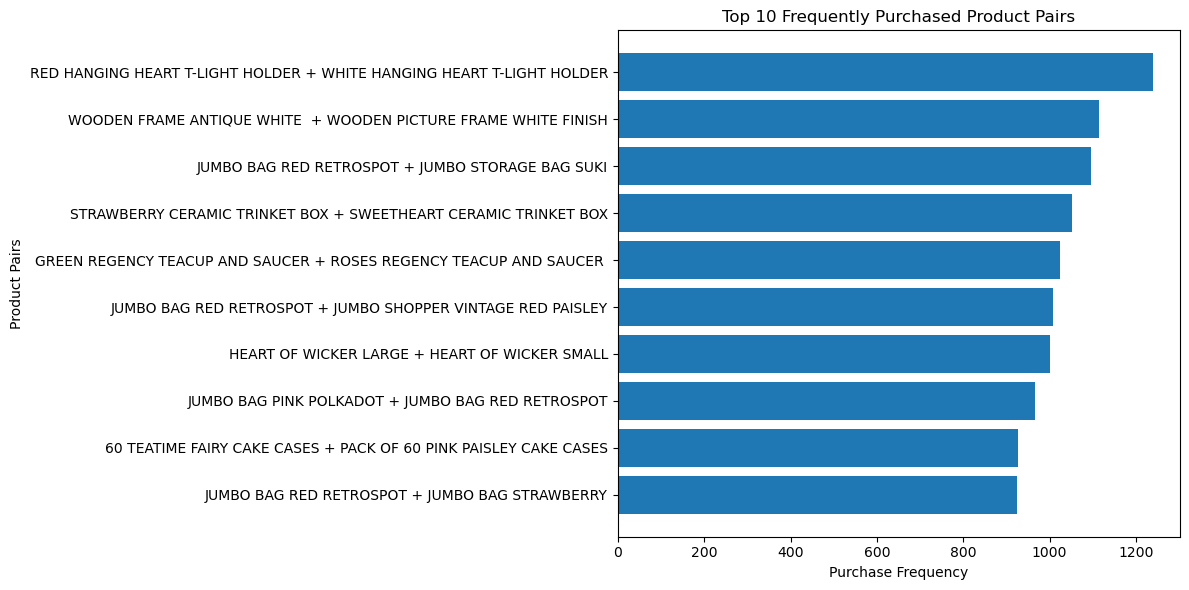

In [31]:
import matplotlib.pyplot as plt

pair_df["Pair Name"] = pair_df["Product Pair"].apply(
    lambda x: " + ".join(x)
)

plt.figure(figsize=(12, 6))

plt.barh(
    pair_df["Pair Name"],
    pair_df["Frequency"]
)

plt.xlabel("Purchase Frequency")
plt.ylabel("Product Pairs")
plt.title("Top 10 Frequently Purchased Product Pairs")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [32]:
product_counter = Counter()

for products in basket.values():
    product_counter.update(set(products))

print("Top 10 Products:")

for product, count in product_counter.most_common(10):
    print(product, ":", count)

Top 10 Products:
WHITE HANGING HEART T-LIGHT HOLDER : 5455
REGENCY CAKESTAND 3 TIER : 3918
JUMBO BAG RED RETROSPOT : 3269
ASSORTED COLOUR BIRD ORNAMENT : 2807
PARTY BUNTING : 2674
LUNCH BAG  BLACK SKULL. : 2351
JUMBO STORAGE BAG SUKI : 2329
STRAWBERRY CERAMIC TRINKET BOX : 2310
JUMBO SHOPPER VINTAGE RED PAISLEY : 2192
HEART OF WICKER SMALL : 2151


In [33]:
rules = []

for (product_a, product_b), frequency in pair_counter.items():

    confidence_ab = frequency / product_counter[product_a]

    confidence_ba = frequency / product_counter[product_b]

    rules.append({
        "Product A": product_a,
        "Product B": product_b,
        "Frequency": frequency,
        "Confidence A to B": round(confidence_ab, 4),
        "Confidence B to A": round(confidence_ba, 4)
    })

rules_df = pd.DataFrame(rules)

rules_df.head()

,Product A,Product B,Frequency,Confidence A to B,Confidence B to A
0,WHITE CHERRY LIGHTS,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,0.0494,0.0232
1,WHITE CHERRY LIGHTS,FANCY FONT HOME SWEET HOME DOORMAT,34,0.1399,0.2073
2,WHITE CHERRY LIGHTS,PINK CHERRY LIGHTS,117,0.4815,0.4415
3,WHITE CHERRY LIGHTS,PINK DOUGHNUT TRINKET POT,20,0.0823,0.0289
4,WHITE CHERRY LIGHTS,"RECORD FRAME 7"" SINGLE SIZE",5,0.0206,0.0090


In [34]:
rules_df["Lift"] = rules_df.apply(
    lambda row: (
        row["Frequency"] * total_orders
    ) / (
        product_counter[row["Product A"]] *
        product_counter[row["Product B"]]
    ),
    axis=1
)

rules_df["Lift"] = rules_df["Lift"].round(3)

rules_df.head()

,Product A,Product B,Frequency,Confidence A to B,Confidence B to A,Lift
0,WHITE CHERRY LIGHTS,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,0.0494,0.0232,3.828
1,WHITE CHERRY LIGHTS,FANCY FONT HOME SWEET HOME DOORMAT,34,0.1399,0.2073,34.192
2,WHITE CHERRY LIGHTS,PINK CHERRY LIGHTS,117,0.4815,0.4415,72.816
3,WHITE CHERRY LIGHTS,PINK DOUGHNUT TRINKET POT,20,0.0823,0.0289,4.760
4,WHITE CHERRY LIGHTS,"RECORD FRAME 7"" SINGLE SIZE",5,0.0206,0.0090,1.486


In [35]:
strong_rules = rules_df.sort_values(
    by="Lift",
    ascending=False
)

strong_rules.head(10)

,Product A,Product B,Frequency,Confidence A to B,Confidence B to A,Lift
3349075,DRAWER KNOB ACRYLIC EDWARDIAN GREEN,DRAWERKNOB ACRYLIC EDWARDIAN PURPLE,1,1.0,1.0,40077.0
3371183,"NUMBER TILE VINTAGE FONT, 1","NUMBER TILE VINTAGE FONT, 8",1,1.0,1.0,40077.0
1315962,PINK OWL DECORATION,RED WALL CLOCK,1,1.0,1.0,40077.0
2473220,"PEN, 10 COLOURS - SPACEBOY","TRAY FOR TV DINNER , DOLLY GIRL",1,1.0,1.0,40077.0
213345,DR WHO TOP TRUMPS GAME,RED MINI TAPE MEASURE,1,1.0,1.0,40077.0
2473221,"PEN, 10 COLOURS - SPACEBOY","TRAY FOR TV DINNER ,SPACEBOY",1,1.0,1.0,40077.0
2473239,"TRAY FOR TV DINNER , DOLLY GIRL","TRAY FOR TV DINNER ,SPACEBOY",1,1.0,1.0,40077.0
1315450,LITTLE FLOWER SHOPPER BAG,RED WALL CLOCK,1,1.0,1.0,40077.0
1315443,LITTLE FLOWER SHOPPER BAG,PINK OWL DECORATION,1,1.0,1.0,40077.0
3371318,"NUMBER TILE VINTAGE FONT, 7","NUMBER TILE VINTAGE FONT, 8",1,1.0,1.0,40077.0


In [36]:
business_rules = rules_df[
    (rules_df["Lift"] > 1) &
    (rules_df["Frequency"] >= 10)
].copy()

business_rules = business_rules.sort_values(
    by="Frequency",
    ascending=False
)

business_rules.head(10)

,Product A,Product B,Frequency,Confidence A to B,Confidence B to A,Lift
1512,RED HANGING HEART T-LIGHT HOLDER,WHITE HANGING HEART T-LIGHT HOLDER,1240,0.7045,0.2273,5.176
29295,WOODEN FRAME ANTIQUE WHITE,WOODEN PICTURE FRAME WHITE FINISH,1114,0.5410,0.5553,10.809
2397423,JUMBO BAG RED RETROSPOT,JUMBO STORAGE BAG SUKI,1096,0.3353,0.4706,5.769
17628,STRAWBERRY CERAMIC TRINKET BOX,SWEETHEART CERAMIC TRINKET BOX,1052,0.4554,0.7099,12.315
2822322,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,1023,0.7634,0.7255,21.699
2397421,JUMBO BAG RED RETROSPOT,JUMBO SHOPPER VINTAGE RED PAISLEY,1008,0.3084,0.4599,5.638
2255504,HEART OF WICKER LARGE,HEART OF WICKER SMALL,1001,0.5128,0.4654,9.555
3031391,JUMBO BAG PINK POLKADOT,JUMBO BAG RED RETROSPOT,966,0.6694,0.2955,8.207
1643,60 TEATIME FAIRY CAKE CASES,PACK OF 60 PINK PAISLEY CAKE CASES,926,0.4354,0.4646,8.755
2393634,JUMBO BAG RED RETROSPOT,JUMBO BAG STRAWBERRY,925,0.2830,0.4987,6.113


In [37]:
for index, row in business_rules.head(10).iterrows():

    print("If a customer buys:", row["Product A"])

    print("Recommend:", row["Product B"])

    print("Frequency:", row["Frequency"])

    print("Confidence:", row["Confidence A to B"])

    print("Lift:", row["Lift"])

    print("-" * 60)

If a customer buys: RED HANGING HEART T-LIGHT HOLDER
Recommend: WHITE HANGING HEART T-LIGHT HOLDER
Frequency: 1240
Confidence: 0.7045
Lift: 5.176
------------------------------------------------------------
If a customer buys: WOODEN FRAME ANTIQUE WHITE 
Recommend: WOODEN PICTURE FRAME WHITE FINISH
Frequency: 1114
Confidence: 0.541
Lift: 10.809
------------------------------------------------------------
If a customer buys: JUMBO BAG RED RETROSPOT
Recommend: JUMBO STORAGE BAG SUKI
Frequency: 1096
Confidence: 0.3353
Lift: 5.769
------------------------------------------------------------
If a customer buys: STRAWBERRY CERAMIC TRINKET BOX
Recommend: SWEETHEART CERAMIC TRINKET BOX
Frequency: 1052
Confidence: 0.4554
Lift: 12.315
------------------------------------------------------------
If a customer buys: GREEN REGENCY TEACUP AND SAUCER
Recommend: ROSES REGENCY TEACUP AND SAUCER 
Frequency: 1023
Confidence: 0.7634
Lift: 21.699
------------------------------------------------------------

In [38]:
recommendations = business_rules[
    [
        "Product A",
        "Product B",
        "Frequency",
        "Confidence A to B",
        "Lift"
    ]
].head(10)

recommendations

,Product A,Product B,Frequency,Confidence A to B,Lift
1512,RED HANGING HEART T-LIGHT HOLDER,WHITE HANGING HEART T-LIGHT HOLDER,1240,0.7045,5.176
29295,WOODEN FRAME ANTIQUE WHITE,WOODEN PICTURE FRAME WHITE FINISH,1114,0.5410,10.809
2397423,JUMBO BAG RED RETROSPOT,JUMBO STORAGE BAG SUKI,1096,0.3353,5.769
17628,STRAWBERRY CERAMIC TRINKET BOX,SWEETHEART CERAMIC TRINKET BOX,1052,0.4554,12.315
2822322,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,1023,0.7634,21.699
2397421,JUMBO BAG RED RETROSPOT,JUMBO SHOPPER VINTAGE RED PAISLEY,1008,0.3084,5.638
2255504,HEART OF WICKER LARGE,HEART OF WICKER SMALL,1001,0.5128,9.555
3031391,JUMBO BAG PINK POLKADOT,JUMBO BAG RED RETROSPOT,966,0.6694,8.207
1643,60 TEATIME FAIRY CAKE CASES,PACK OF 60 PINK PAISLEY CAKE CASES,926,0.4354,8.755
2393634,JUMBO BAG RED RETROSPOT,JUMBO BAG STRAWBERRY,925,0.2830,6.113


In [41]:
print("Pair DataFrame:", pair_df.shape)
print("Rules DataFrame:", rules_df.shape)
print("Recommendations:", recommendations.shape)

Pair DataFrame: (10, 4)
Rules DataFrame: (5904713, 6)
Recommendations: (10, 5)


In [42]:
top_rules = rules_df.sort_values(
    by="Lift",
    ascending=False
).head(10000)

print("Rules selected:", len(top_rules))

Rules selected: 10000


In [43]:
with pd.ExcelWriter(
    "Day29_Product_Basket_Analysis.xlsx",
    engine="openpyxl"
) as writer:

    pair_df.to_excel(
        writer,
        sheet_name="Top Product Pairs",
        index=False
    )

    top_rules.to_excel(
        writer,
        sheet_name="Top 10000 Rules",
        index=False
    )

    recommendations.to_excel(
        writer,
        sheet_name="Recommendations",
        index=False
    )

print("Excel report exported successfully!")

Excel report exported successfully!


In [44]:
import os

print("File exists:", os.path.exists(
    "Day29_Product_Basket_Analysis.xlsx"
))

File exists: True


In [45]:
check = pd.ExcelFile("Day29_Product_Basket_Analysis.xlsx")

print(check.sheet_names)

['Top Product Pairs', 'Top 10000 Rules', 'Recommendations']


In [46]:
business_rules.head(10)

,Product A,Product B,Frequency,Confidence A to B,Confidence B to A,Lift
1512,RED HANGING HEART T-LIGHT HOLDER,WHITE HANGING HEART T-LIGHT HOLDER,1240,0.7045,0.2273,5.176
29295,WOODEN FRAME ANTIQUE WHITE,WOODEN PICTURE FRAME WHITE FINISH,1114,0.5410,0.5553,10.809
2397423,JUMBO BAG RED RETROSPOT,JUMBO STORAGE BAG SUKI,1096,0.3353,0.4706,5.769
17628,STRAWBERRY CERAMIC TRINKET BOX,SWEETHEART CERAMIC TRINKET BOX,1052,0.4554,0.7099,12.315
2822322,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,1023,0.7634,0.7255,21.699
2397421,JUMBO BAG RED RETROSPOT,JUMBO SHOPPER VINTAGE RED PAISLEY,1008,0.3084,0.4599,5.638
2255504,HEART OF WICKER LARGE,HEART OF WICKER SMALL,1001,0.5128,0.4654,9.555
3031391,JUMBO BAG PINK POLKADOT,JUMBO BAG RED RETROSPOT,966,0.6694,0.2955,8.207
1643,60 TEATIME FAIRY CAKE CASES,PACK OF 60 PINK PAISLEY CAKE CASES,926,0.4354,0.4646,8.755
2393634,JUMBO BAG RED RETROSPOT,JUMBO BAG STRAWBERRY,925,0.2830,0.4987,6.113
